# FoodBD - Bangladeshi Food Classification with a CNN (PyTorch)

**CNN Implementation and Result Analysis**


In [ ]:

import torch
import torch.nn as nn
import torch.nn.functional as F

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
import numpy as np
import os, zipfile, yaml
from PIL import Image

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

torch.manual_seed(0)
np.random.seed(0)

Using device: cuda


## 2. Get the data

We use the **FoodBD** dataset (*A Polygon-Annotated Meal Image Dataset of Bangladeshi food*). It is already split into `train`, `valid` and `test`, and has **67 food classes**:

```
FoodBD/
├── data.yaml        (the 67 class names)
├── train/  images/ (2473 meal photos)   labels/ (polygon .txt files)
├── valid/  images/ (697 meal photos)    labels/
└── test/   images/ (353 meal photos)    labels/
```

The dataset zip is in **Google Drive**. We mount Drive and unzip it.
👉 **Change `ZIP_PATH` below if your zip is in a different Drive folder.**

In [ ]:


import shutil
from google.colab import drive
drive.mount("/content/drive")

def find_foodbd_dir(root):
    for current, subdirs, files in os.walk(root):
        if "data.yaml" in files and "train" in subdirs and "valid" in subdirs:
            return current
    return None

LOCAL_DIR = "/content/FoodBD"

if not os.path.exists(LOCAL_DIR):
    drive_dir = find_foodbd_dir("/content/drive/MyDrive")
    if drive_dir is None:
        raise FileNotFoundError("FoodBD folder not found in My Drive. Check that the folder with data.yaml is in 'My Drive'.")
    print("Found in Drive:", drive_dir)
    print("Copying to local disk (takes 1-3 minutes)...")
    shutil.copytree(drive_dir, LOCAL_DIR)

base = LOCAL_DIR

class_names_all = yaml.safe_load(open(os.path.join(base, "data.yaml")))["names"]
print("Dataset folder:", base)
print("Number of classes:", len(class_names_all))
for split in ["train", "valid", "test"]:
    print(split, "images:", len(os.listdir(os.path.join(base, split, "images"))))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Found in Drive: /content/drive/MyDrive/FoodBD A Polygon-Annotated Meal Image Dataset of B/root/FoodBD
Copying to local disk (takes 1-3 minutes)...
Dataset folder: /content/FoodBD
Number of classes: 67
train images: 2497
valid images: 697
test images: 353


### Turn the meal photos into one-food-per-image folders

A FoodBD photo is a whole **meal plate** with several foods on it (e.g. rice + daal + fish). Each food is marked by a **polygon** in the `labels/*.txt` file (format: `class_id x1 y1 x2 y2 ...`, coordinates between 0 and 1).

Our CNN predicts **one class per image**, so we **crop every annotated food item** using the box around its polygon and save it into a folder named after its class:

```
FoodBD_crops/
├── train/  achar/  apple/  ...  watermelon/
├── valid/  achar/  apple/  ...  watermelon/
└── test/   achar/  apple/  ...  watermelon/
```

Because the images are now sorted into class folders, PyTorch's `ImageFolder` labels them automatically.

In [ ]:
crop_dir = "FoodBD_crops"

def make_crops(foodbd_dir, out_dir, min_size=16, pad=0.05):
    counts = {}
    for split in ["train", "valid", "test"]:

        for name in class_names_all:
            os.makedirs(os.path.join(out_dir, split, name), exist_ok=True)
        img_dir = os.path.join(foodbd_dir, split, "images")
        lbl_dir = os.path.join(foodbd_dir, split, "labels")
        n = 0
        for fname in sorted(os.listdir(img_dir)):
            stem = os.path.splitext(fname)[0]
            lbl_path = os.path.join(lbl_dir, stem + ".txt")
            if not os.path.exists(lbl_path):
                continue
            img = Image.open(os.path.join(img_dir, fname)).convert("RGB")
            W, H = img.size
            for k, line in enumerate(open(lbl_path)):
                parts = line.split()
                if len(parts) < 7:
                    continue
                cls = int(parts[0])
                xs = [float(v) * W for v in parts[1::2]]
                ys = [float(v) * H for v in parts[2::2]]
                x1, x2, y1, y2 = min(xs), max(xs), min(ys), max(ys)
                pw, ph = (x2 - x1) * pad, (y2 - y1) * pad
                x1, y1 = max(0, x1 - pw), max(0, y1 - ph)
                x2, y2 = min(W, x2 + pw), min(H, y2 + ph)
                if (x2 - x1) < min_size or (y2 - y1) < min_size:
                    continue
                img.crop((int(x1), int(y1), int(x2), int(y2))).save(
                    os.path.join(out_dir, split, class_names_all[cls], f"{stem}_{k}.jpg"), quality=95)
                n += 1
        counts[split] = n
    return counts

if not os.path.exists(crop_dir):
    print("Cropping food items (takes ~1 minute)...")
    print(make_crops(base, crop_dir))

train_dir = os.path.join(crop_dir, "train")
val_dir   = os.path.join(crop_dir, "valid")
test_dir  = os.path.join(crop_dir, "test")
print("train:", len(os.listdir(train_dir)), "class folders")

Cropping food items (takes ~1 minute)...
{'train': 9359, 'valid': 2746, 'test': 1373}
train: 67 class folders


## 3. Load the images — **basic transform only**


In [ ]:

IMG_SIZE = 64
BATCH_SIZE = 32
LEARNING_RATE = 0.0005
EPOCHS = 12


basic_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])

train_ds = datasets.ImageFolder(train_dir, transform=basic_transform, allow_empty=True)
val_ds   = datasets.ImageFolder(val_dir,   transform=basic_transform, allow_empty=True)
test_ds  = datasets.ImageFolder(test_dir,  transform=basic_transform, allow_empty=True)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

num_classes = len(train_ds.classes)
print("Number of classes:", num_classes)
print("Train images:", len(train_ds))
print("Val images  :", len(val_ds))
print("Test images :", len(test_ds))

Number of classes: 67
Train images: 9359
Val images  : 2746
Test images : 1373


### Look at a few images


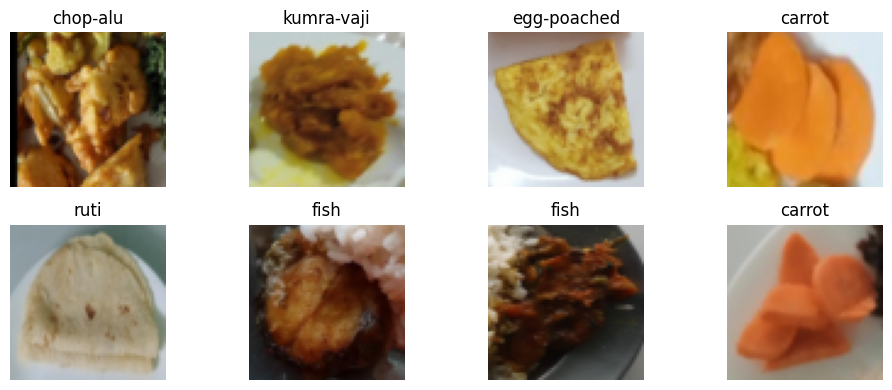

In [ ]:

images, labels = next(iter(train_loader))
class_names = train_ds.classes

plt.figure(figsize=(10, 4))
for i in range(8):
    plt.subplot(2, 4, i + 1)

    plt.imshow(images[i].permute(1, 2, 0))
    plt.title(class_names[labels[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=67, p_dropout=0.0):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool  = nn.MaxPool2d(2, 2)


        self.dropout = nn.Dropout(p_dropout)
        self.fc1 = nn.Linear(64 * (IMG_SIZE // 8) * (IMG_SIZE // 8), 128)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

model = SimpleCNN(num_classes=num_classes, p_dropout=0.0).to(device)
print(model)

n_params = sum(p.numel() for p in model.parameters())
print(f"\nTotal trainable parameters: {n_params:,}")

SimpleCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.0, inplace=False)
  (fc1): Linear(in_features=4096, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=67, bias=True)
)

Total trainable parameters: 556,643


## 5. Train the model


In [ ]:
def train_model(model, train_loader, val_loader, epochs=15, lr=1e-3):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):

        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * imgs.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
        train_loss = running_loss / total
        train_acc = correct / total

        model.eval()
        running_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(device), labels.to(device)
                outputs = model(imgs)
                loss = criterion(outputs, labels)
                running_loss += loss.item() * imgs.size(0)
                correct += (outputs.argmax(1) == labels).sum().item()
                total += labels.size(0)
        val_loss = running_loss / total
        val_acc = correct / total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(f"Epoch {epoch+1:2d}/{epochs}  "
              f"train_loss={train_loss:.3f} train_acc={train_acc:.3f}  |  "
              f"val_loss={val_loss:.3f} val_acc={val_acc:.3f}")

    return history


history = train_model(model, train_loader, val_loader, epochs=EPOCHS, lr=LEARNING_RATE)

Epoch  1/12  train_loss=3.190 train_acc=0.190  |  val_loss=2.799 val_acc=0.292
Epoch  2/12  train_loss=2.611 train_acc=0.329  |  val_loss=2.336 val_acc=0.411
Epoch  3/12  train_loss=2.216 train_acc=0.431  |  val_loss=2.160 val_acc=0.435
Epoch  4/12  train_loss=1.961 train_acc=0.494  |  val_loss=1.912 val_acc=0.498
Epoch  5/12  train_loss=1.792 train_acc=0.535  |  val_loss=1.775 val_acc=0.542
Epoch  6/12  train_loss=1.634 train_acc=0.570  |  val_loss=1.717 val_acc=0.561
Epoch  7/12  train_loss=1.519 train_acc=0.593  |  val_loss=1.696 val_acc=0.568
Epoch  8/12  train_loss=1.428 train_acc=0.613  |  val_loss=1.643 val_acc=0.575
Epoch  9/12  train_loss=1.343 train_acc=0.634  |  val_loss=1.615 val_acc=0.583
Epoch 10/12  train_loss=1.245 train_acc=0.654  |  val_loss=1.596 val_acc=0.588
Epoch 11/12  train_loss=1.175 train_acc=0.670  |  val_loss=1.605 val_acc=0.596
Epoch 12/12  train_loss=1.106 train_acc=0.694  |  val_loss=1.585 val_acc=0.601


## 6. Visualize the filters 👀

Two useful things to look at:

1. **The filters themselves** — the actual `3 × 3` weight grids of the first convolution layer. Because the first layer takes a 3-channel (RGB) image, each filter is a tiny colour patch. They tend to become **edge / colour detectors**.
2. **Feature maps** — the *response* of those filters to a real image: bright spots show *where* each pattern was found.

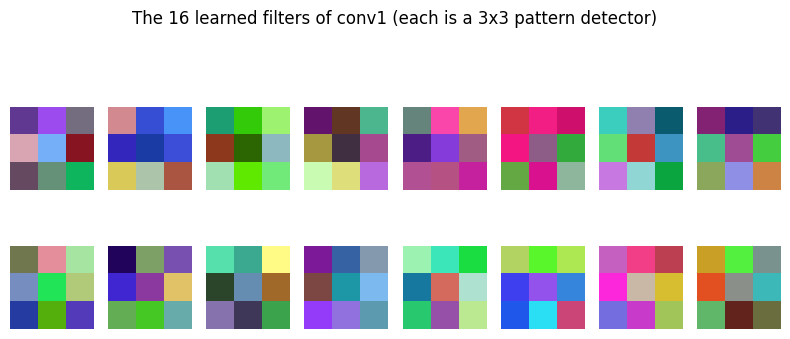

In [ ]:

weights = model.conv1.weight.data.clone().cpu()

w_min, w_max = weights.min(), weights.max()
weights = (weights - w_min) / (w_max - w_min + 1e-8)

plt.figure(figsize=(8, 4))
for i in range(16):
    plt.subplot(2, 8, i + 1)
    plt.imshow(weights[i].permute(1, 2, 0))
    plt.axis("off")
plt.suptitle("The 16 learned filters of conv1 (each is a 3x3 pattern detector)")
plt.tight_layout()
plt.show()

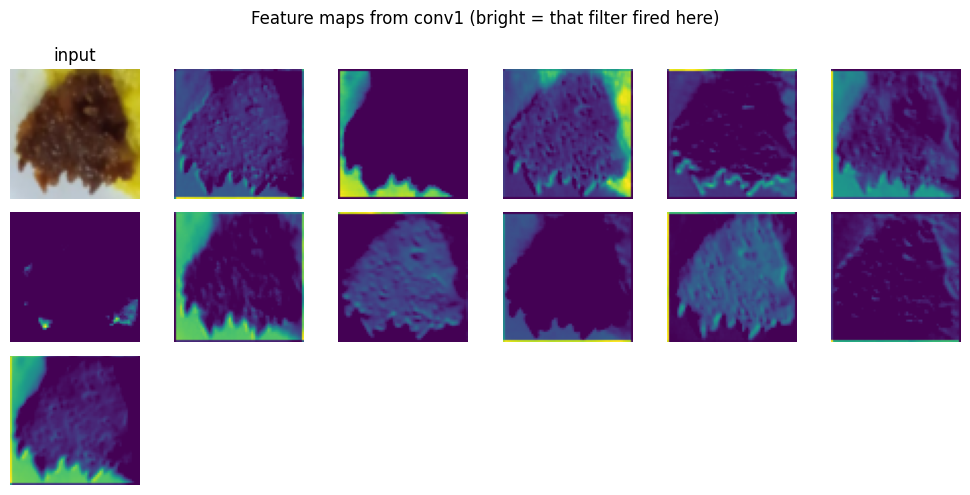

In [ ]:

img, label = val_ds[0]
img_batch = img.unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    feature_maps = F.relu(model.conv1(img_batch)).cpu()[0]

plt.figure(figsize=(10, 5))

plt.subplot(3, 6, 1)
plt.imshow(img.permute(1, 2, 0)); plt.title("input"); plt.axis("off")

for i in range(12):
    plt.subplot(3, 6, i + 2)
    plt.imshow(feature_maps[i], cmap="viridis")
    plt.axis("off")
plt.suptitle("Feature maps from conv1 (bright = that filter fired here)")
plt.tight_layout()
plt.show()

Last conv layer (conv3) output shape: (64, 16, 16)


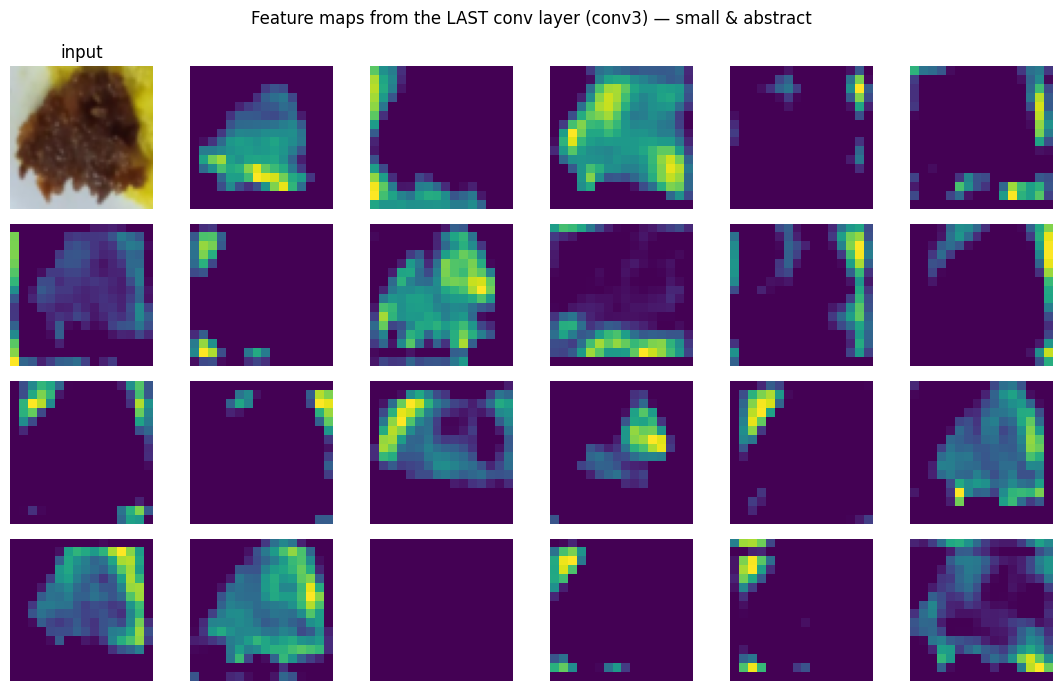

In [ ]:
model.eval()
img, _ = val_ds[0]
x = img.unsqueeze(0).to(device)

with torch.no_grad():
    x = model.pool(F.relu(model.conv1(x)))
    x = model.pool(F.relu(model.conv2(x)))
    last_maps = F.relu(model.conv3(x)).cpu()[0]

print("Last conv layer (conv3) output shape:", tuple(last_maps.shape))

plt.figure(figsize=(11, 7))
plt.subplot(4, 6, 1)
plt.imshow(img.permute(1, 2, 0)); plt.title("input"); plt.axis("off")
for i in range(23):
    plt.subplot(4, 6, i + 2)
    plt.imshow(last_maps[i], cmap="viridis")
    plt.axis("off")
plt.suptitle("Feature maps from the LAST conv layer (conv3) — small & abstract")
plt.tight_layout()
plt.show()

# Result Analysis

## 7. Training diagnostics (accuracy and loss curves)

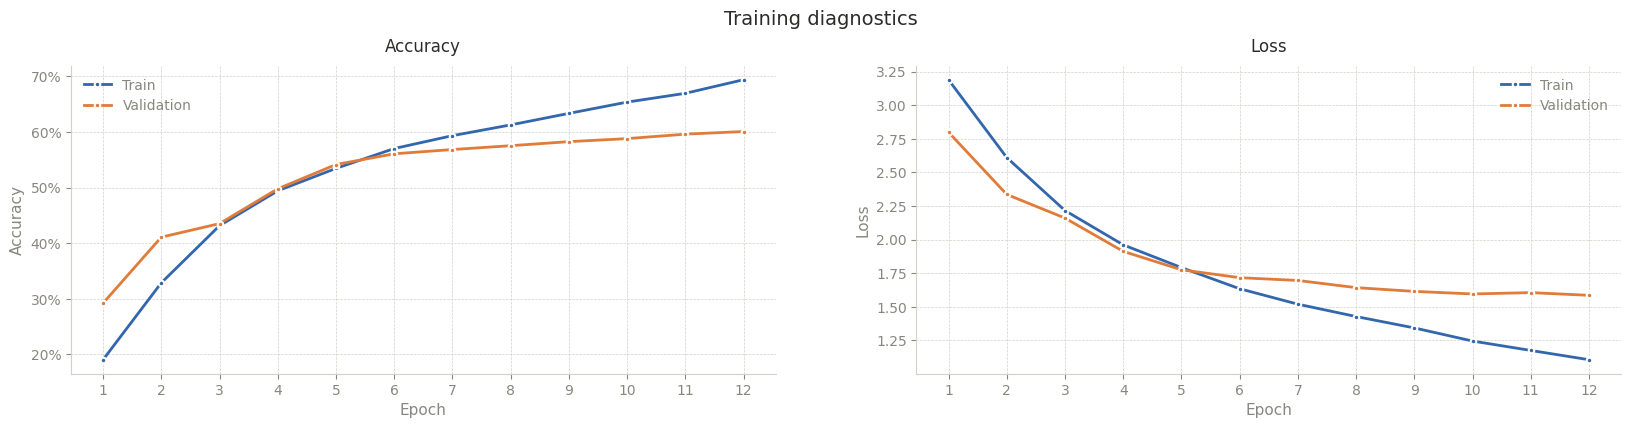

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.gridspec as gridspec
import numpy as np

epochs = EPOCHS
train_losses     = history["train_loss"]
train_accuracies = history["train_acc"]
val_losses       = history["val_loss"]
val_accuracies   = history["val_acc"]

BLUE   = "#3266ad"
ORANGE = "#e07b39"
GRAY   = "#88877f"

plt.rcParams.update({
    "font.family": "sans-serif",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#d3d1c7",
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "grid.color": "#d3d1c7",
    "grid.linewidth": 0.5,
    "grid.linestyle": "--",
    "xtick.color": GRAY,
    "ytick.color": GRAY,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

epochs_number = np.arange(1, epochs + 1)
fig = plt.figure(figsize=(20, 4))
gs  = gridspec.GridSpec(1, 2, figure=fig, wspace=0.2)

ax1 = fig.add_subplot(gs[0])
ax1.plot(epochs_number, train_accuracies, color=BLUE,   lw=2,   label="Train",      marker="o", ms=4, mew=1.5, mec="white")
ax1.plot(epochs_number, val_accuracies,   color=ORANGE, lw=2,   label="Validation", marker="o", ms=4, mew=1.5, mec="white", linestyle="-")
ax1.xaxis.set_major_locator(mticker.MultipleLocator(1))
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x*100:.0f}%"))
ax1.set_xlabel("Epoch", color=GRAY, fontsize=11)
ax1.set_ylabel("Accuracy", color=GRAY, fontsize=11)
ax1.set_title("Accuracy", fontsize=12, fontweight="medium", color="#2c2c2a", pad=10)
ax1.legend(frameon=False, fontsize=10, labelcolor=GRAY)


ax2 = fig.add_subplot(gs[1])
ax2.plot(epochs_number, train_losses, color=BLUE,   lw=2, label="Train",      marker="o", ms=4, mew=1.5, mec="white")
ax2.plot(epochs_number, val_losses,   color=ORANGE, lw=2, label="Validation", marker="o", ms=4, mew=1.5, mec="white", linestyle="-")
ax2.xaxis.set_major_locator(mticker.MultipleLocator(1))
ax2.yaxis.set_major_locator(mticker.MultipleLocator(0.25))
ax2.set_xlabel("Epoch", color=GRAY, fontsize=11)
ax2.set_ylabel("Loss",  color=GRAY, fontsize=11)
ax2.set_title("Loss", fontsize=12, fontweight="medium", color="#2c2c2a", pad=10)
ax2.legend(frameon=False, fontsize=10, labelcolor=GRAY)

fig.suptitle("Training diagnostics", fontsize=14, fontweight="medium", color="#2c2c2a", y=1.02)
plt.savefig("training_curves.pdf", bbox_inches="tight", dpi=150)
plt.show()

## 8. Predict one random test image

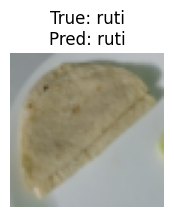

In [ ]:
model.eval()
ix = torch.randint(0, len(test_ds), ())
img = test_ds[ix][0].unsqueeze(0).to(device)
np_output = model(img).cpu().detach().numpy()
pred = np.exp(np_output)/np.sum(np.exp(np_output))
plt.figure(figsize=(2,2))
plt.imshow(img.squeeze(0).permute(1,2,0).cpu().detach().numpy())
plt.title(f"True: {test_ds.classes[test_ds[ix][1]]}\nPred: {test_ds.classes[pred[0].argmax()]}")
plt.axis("off")
plt.show()

## 9. Misclassified test images

Total test samples: 1373
Total misclassified samples: 557
Test accuracy: 0.5943


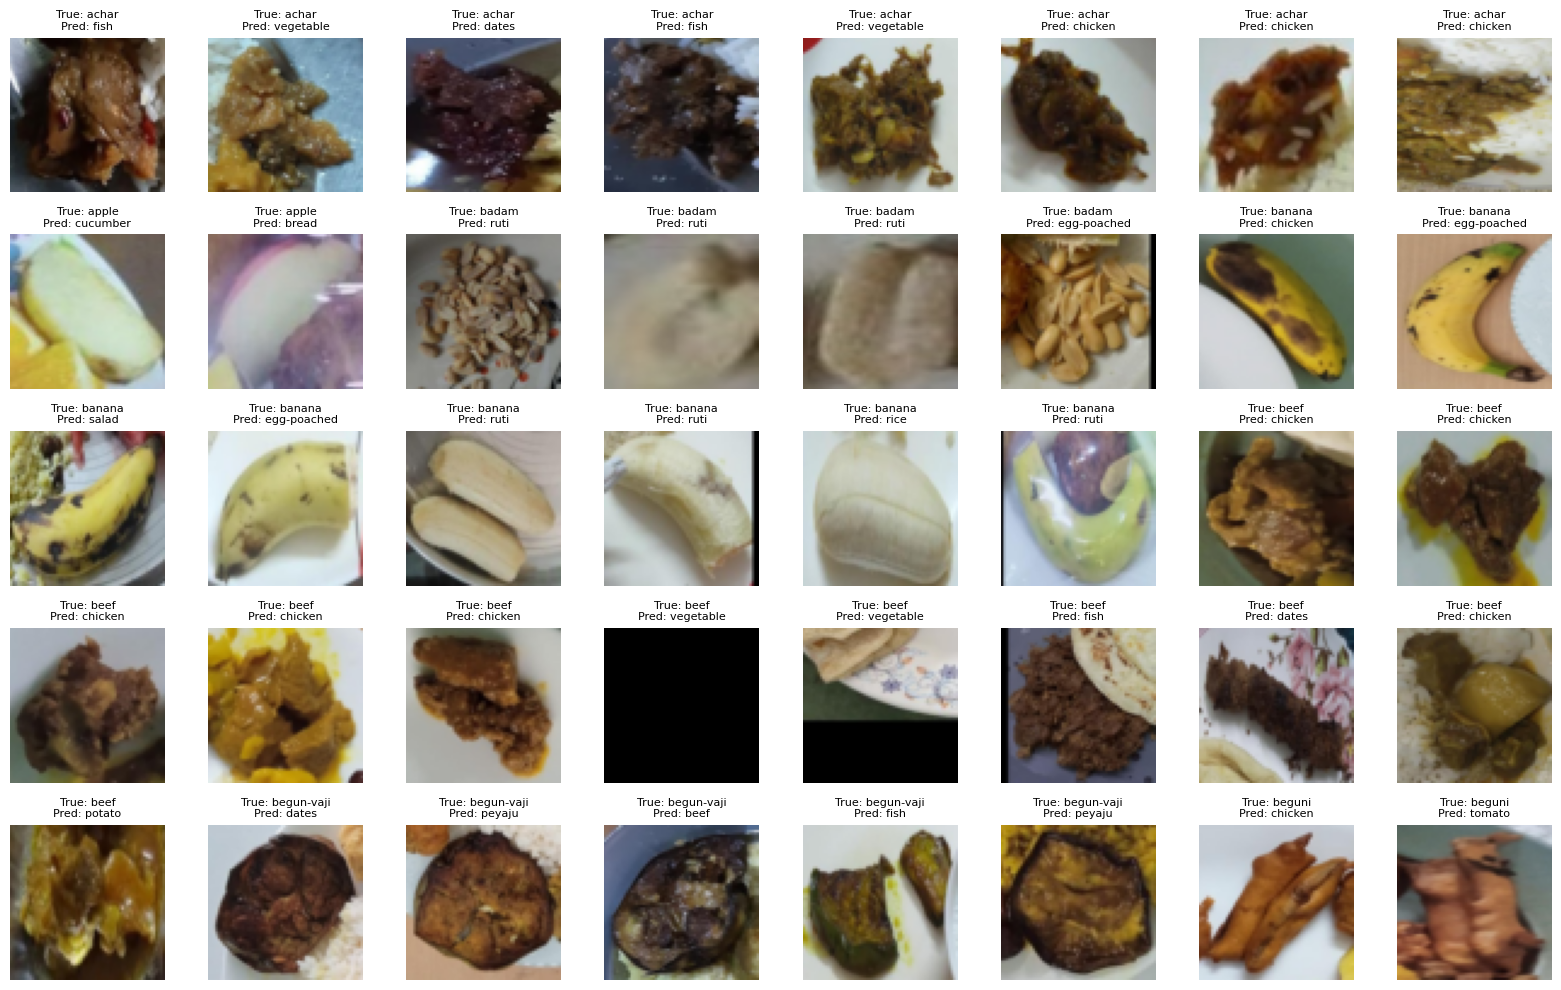

In [ ]:
import torch
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix
import seaborn as sns

class_names = test_ds.classes

model.eval()
misclassified = []
all_preds = []
all_labels = []


with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

        for img, true, pred in zip(images, labels, preds):
            if true != pred:
                misclassified.append((img.cpu(), true.cpu(), pred.cpu()))

print(f"Total test samples: {len(all_labels)}")
print(f"Total misclassified samples: {len(misclassified)}")
print(f"Test accuracy: {1 - len(misclassified)/len(all_labels):.4f}")


num_rows = 5
num_cols = 8
num_to_show = num_rows * num_cols
num_to_show = min(num_to_show, len(misclassified))

fig, axes = plt.subplots(num_rows, num_cols, figsize=(num_cols*2, num_rows*2))
axes = axes.flatten()

for idx in range(num_to_show):
    img, true, pred = misclassified[idx]
    img = img.permute(1, 2, 0)
    img = img * 255
    img = img.numpy().astype(np.uint8)

    axes[idx].imshow(img)
    axes[idx].set_title(f"True: {class_names[true]}\nPred: {class_names[pred]}", fontsize=8)
    axes[idx].axis('off')


for idx in range(num_to_show, len(axes)):
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

## 10. Confusion matrix and per-class report

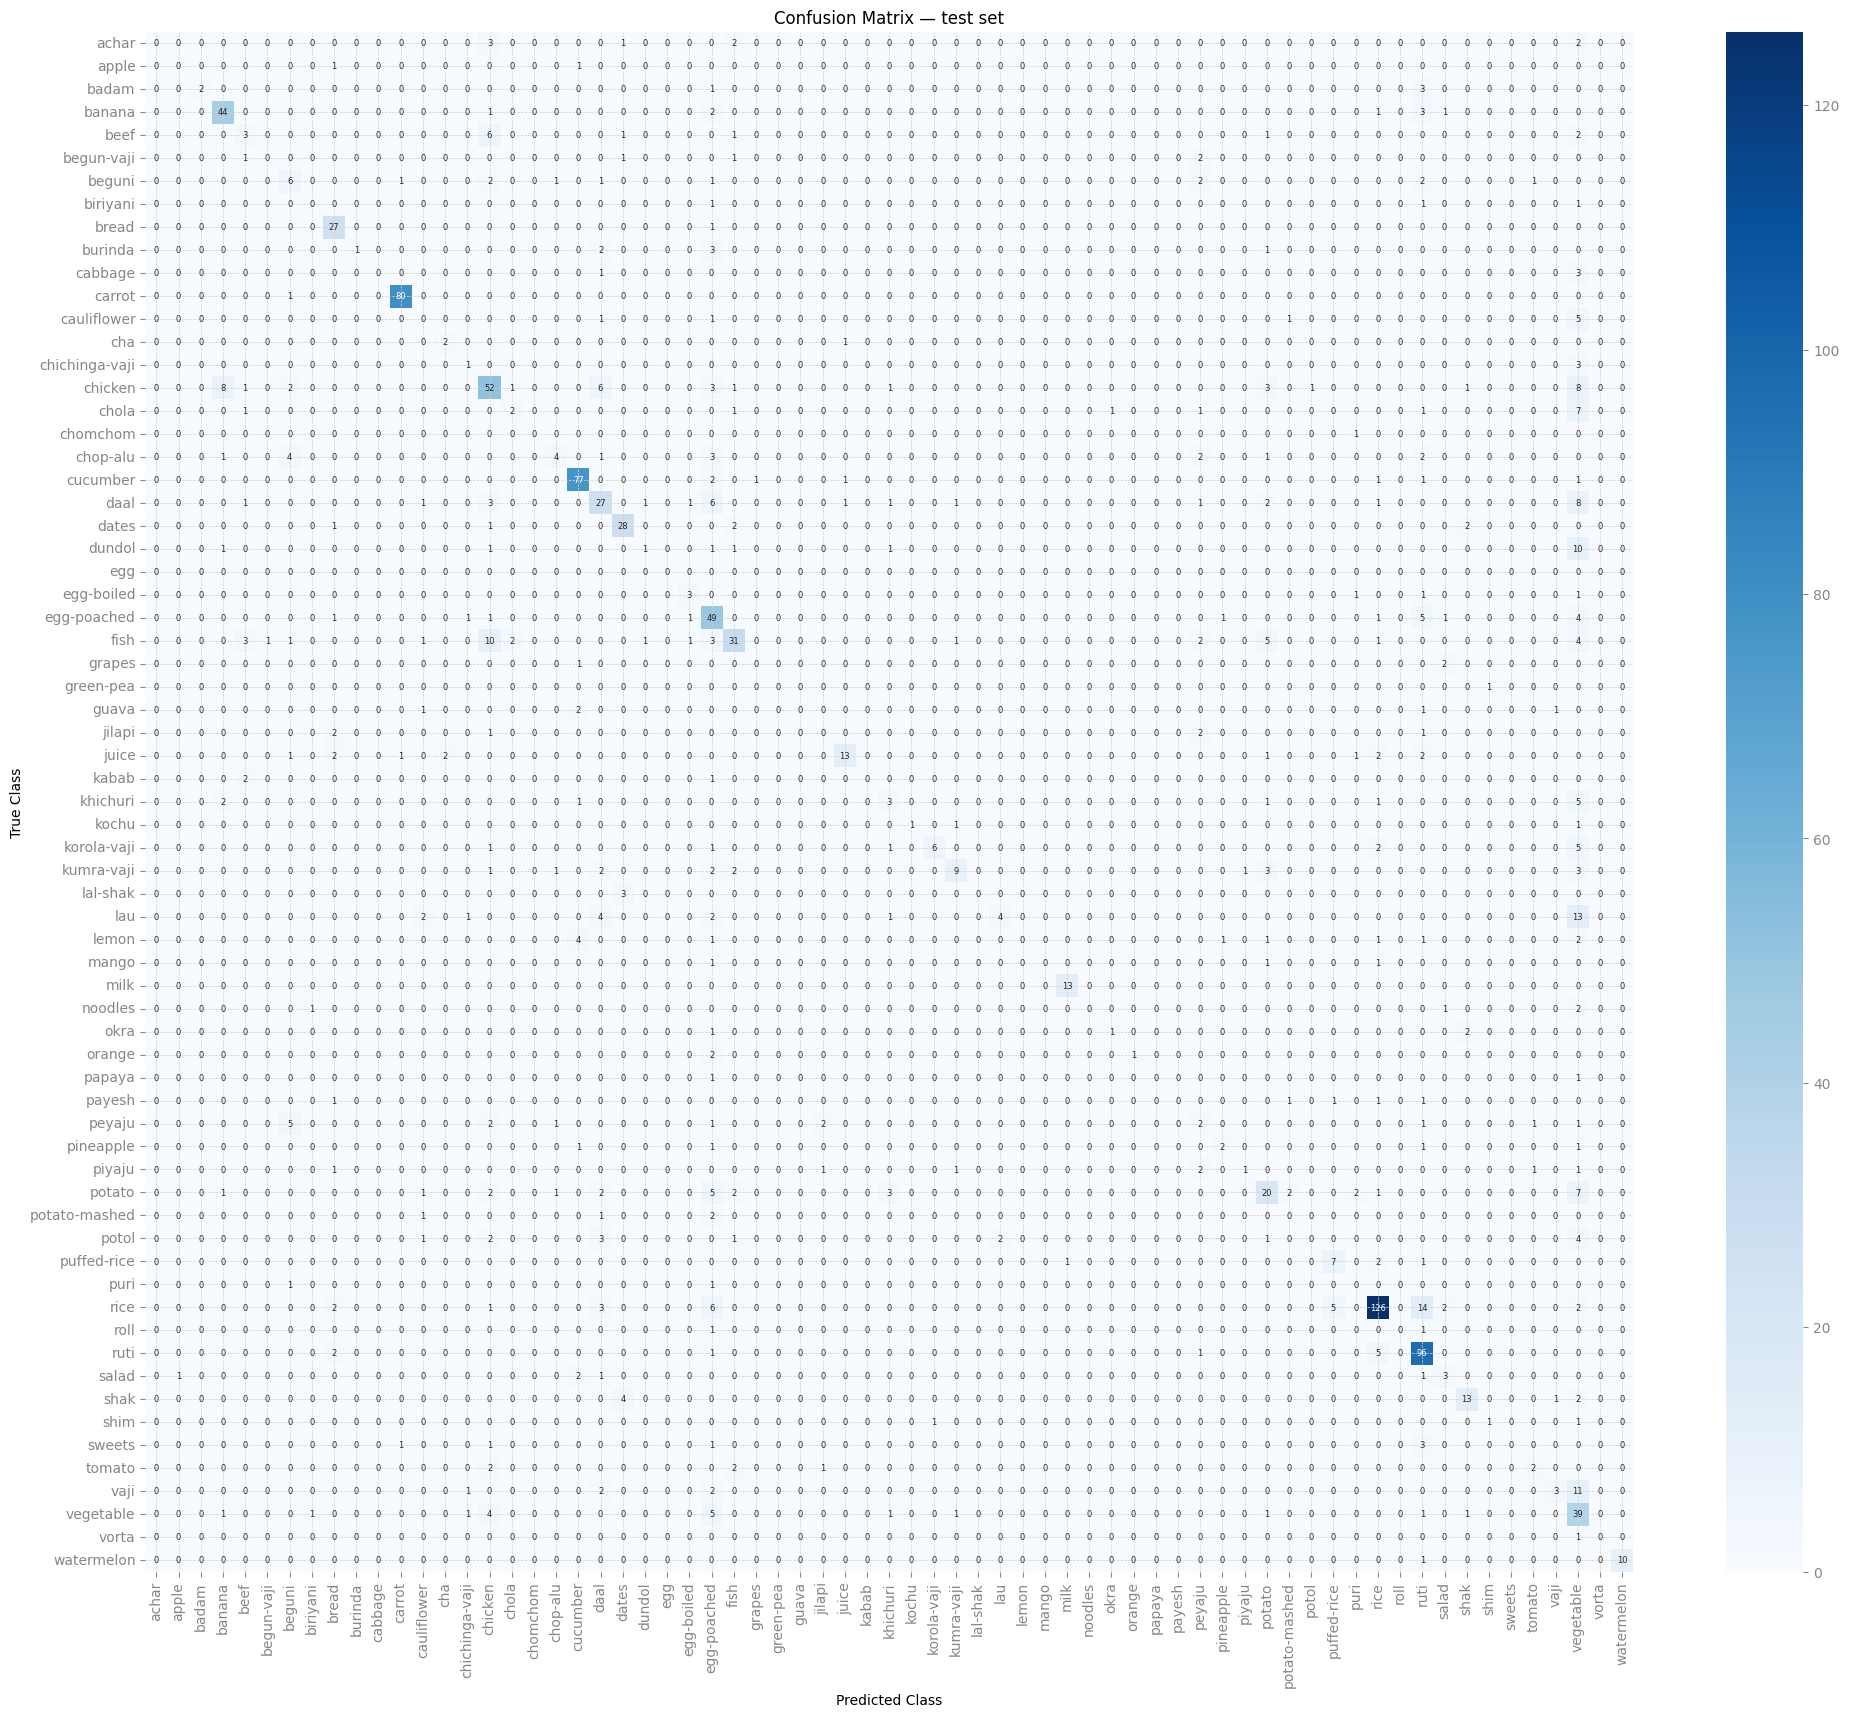

In [ ]:

cm = confusion_matrix(all_labels, all_preds, labels=range(len(class_names)))
plt.figure(figsize=(24,20))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', annot_kws={"size": 6},
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Confusion Matrix — test set")
plt.show()

In [ ]:
from sklearn.metrics import classification_report

present = sorted(set(all_labels))
print(classification_report(all_labels, all_preds, labels=present,
                            target_names=[class_names[i] for i in present], zero_division=0))

                precision    recall  f1-score   support

         achar       0.00      0.00      0.00         8
         apple       0.00      0.00      0.00         2
         badam       1.00      0.33      0.50         6
        banana       0.76      0.85      0.80        52
          beef       0.25      0.21      0.23        14
    begun-vaji       0.00      0.00      0.00         5
        beguni       0.29      0.35      0.32        17
      biriyani       0.00      0.00      0.00         3
         bread       0.68      0.96      0.79        28
       burinda       1.00      0.14      0.25         7
       cabbage       0.00      0.00      0.00         4
        carrot       0.96      0.99      0.98        81
   cauliflower       0.00      0.00      0.00         8
           cha       0.50      0.67      0.57         3
chichinga-vaji       0.20      0.25      0.22         4
       chicken       0.54      0.59      0.56        88
         chola       0.40      0.14      0.21  